# Assignment 4 

Name: Jakkarin Promsee <br>
Student ID: 67070501009

## 0. Setup

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

pd.set_option('display.max_columns', 100)
print("sklearn :", sklearn.__version__)

sklearn : 1.8.0


## 1. Load dataset

In [45]:
df = pd.read_csv('MBA.csv')

print("shape :", df.shape)
print("cols  :", list(df.columns))
df.head()

shape : (6194, 10)
cols  : ['application_id', 'gender', 'international', 'gpa', 'major', 'race', 'gmat', 'work_exp', 'work_industry', 'admission']


,application_id,gender,international,gpa,major,race,gmat,work_exp,work_industry,admission
0,1,Female,False,3.30,Business,Asian,620.0,3.0,Financial Services,Admit
1,2,Male,False,3.28,Humanities,Black,680.0,5.0,Investment Management,NaN
2,3,Female,True,3.30,Business,NaN,710.0,5.0,Technology,Admit
3,4,Male,False,3.47,STEM,Black,690.0,6.0,Technology,NaN
4,5,Male,False,3.35,STEM,Hispanic,590.0,5.0,Consulting,NaN


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6194 entries, 0 to 6193
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   application_id  6194 non-null   int64  
 1   gender          6194 non-null   object 
 2   international   6194 non-null   bool   
 3   gpa             6194 non-null   float64
 4   major           6194 non-null   object 
 5   race            4352 non-null   object 
 6   gmat            6194 non-null   float64
 7   work_exp        6194 non-null   float64
 8   work_industry   6194 non-null   object 
 9   admission       1000 non-null   object 
dtypes: bool(1), float64(3), int64(1), object(5)
memory usage: 441.7+ KB


## 2. Target: admission -> admit 1/0

`admission` มี 3 ค่า Admit / Waitlist / NaN โดย **NaN = Deny** <br/>

In [47]:
df['admission'].value_counts()

admission
Admit       900
Waitlist    100
Name: count, dtype: int64

In [48]:
df['admission'].value_counts(dropna=False)

admission
NaN         5194
Admit        900
Waitlist     100
Name: count, dtype: int64

In [49]:
df['admit'] = (df['admission'] == 'Admit').astype(int)

# เช็คว่า map ถูก แถว NaN ต้องตกไปช่อง 0 ให้หมด
print(pd.crosstab(df['admission'].fillna('(NaN = Deny)'), df['admit']))
print("\nadmit rate = %.4f" % df['admit'].mean())

admit            0    1
admission              
(NaN = Deny)  5194    0
Admit            0  900
Waitlist       100    0

admit rate = 0.1453


> positive class มีแค่ 14.5% -> imbalanced

## 3. Explore and clean data

In [50]:
# application_id เป็นเลขรัน ไม่ใช่ feature / admission ใช้ทำ target ไปแล้ว
df = df.drop(columns=['application_id', 'admission'])

In [51]:
df.shape

(6194, 9)

In [52]:
df.isna().sum()

gender              0
international       0
gpa                 0
major               0
race             1842
gmat                0
work_exp            0
work_industry       0
admit               0
dtype: int64

In [53]:
df.select_dtypes('number').describe()

,gpa,gmat,work_exp,admit
count,6194.000000,6194.000000,6194.000000,6194.000000
mean,3.250714,651.092993,5.016952,0.145302
std,0.151541,49.294883,1.032432,0.352433
min,2.650000,570.000000,1.000000,0.000000
25%,3.150000,610.000000,4.000000,0.000000
50%,3.250000,650.000000,5.000000,0.000000
75%,3.350000,680.000000,6.000000,0.000000
max,3.770000,780.000000,9.000000,1.000000


In [54]:
df.select_dtypes(['object', 'bool']).describe()

,gender,international,major,race,work_industry
count,6194,6194,6194,4352,6194
unique,2,2,3,5,14
top,Male,False,Humanities,White,Consulting
freq,3943,4352,2481,1456,1619


In [55]:
for c in df.select_dtypes('object').columns:
    print(df[c].value_counts(dropna=False), "\n")

gender
Male      3943
Female    2251
Name: count, dtype: int64 

major
Humanities    2481
STEM          1875
Business      1838
Name: count, dtype: int64 

race
NaN         1842
White       1456
Asian       1147
Black        916
Hispanic     596
Other        237
Name: count, dtype: int64 

work_industry
Consulting               1619
PE/VC                     907
Technology                716
Nonprofit/Gov             651
Investment Banking        580
Financial Services        451
Other                     421
Health Care               334
Investment Management     166
CPG                       114
Real Estate               111
Media/Entertainment        59
Retail                     33
Energy                     32
Name: count, dtype: int64 



## 4. race ที่ว่างอยู่ 1842 แถว

เช็คก่อนว่าหายแบบสุ่มหรือหายมีแพทเทิร์น ค่อยตัดสินใจว่าจะ drop หรือ fill

In [56]:
print(pd.crosstab(df['race'].isna(), df['international']))

international  False  True 
race                       
False           4352      0
True               0   1842


In [57]:
df['race'] = df['race'].fillna('International')

# เติมแล้ว race_International จะซ้ำกับ international ทุกแถว เก็บทั้งคู่ importance โดนหารกัน
print("duplicate :", (df['race'] == 'International').equals(df['international']))
df = df.drop(columns='international')

print(df['race'].value_counts())

duplicate : True
race
International    1842
White            1456
Asian            1147
Black             916
Hispanic          596
Other             237
Name: count, dtype: int64


## 5. Encoding

In [58]:
df_num = df.select_dtypes('number').drop(columns='admit')
df_cat = df.select_dtypes('object')

print("numeric     :", list(df_num.columns))
print("categorical :", list(df_cat.columns))

numeric     : ['gpa', 'gmat', 'work_exp']
categorical : ['gender', 'major', 'race', 'work_industry']


In [59]:
df_cat_bin = pd.get_dummies(df_cat, drop_first=True)

print("shape :", df_cat_bin.shape)
df_cat_bin.head()

shape : (6194, 21)


,gender_Male,major_Humanities,major_STEM,race_Black,race_Hispanic,race_International,race_Other,race_White,work_industry_Consulting,work_industry_Energy,work_industry_Financial Services,work_industry_Health Care,work_industry_Investment Banking,work_industry_Investment Management,work_industry_Media/Entertainment,work_industry_Nonprofit/Gov,work_industry_Other,work_industry_PE/VC,work_industry_Real Estate,work_industry_Retail,work_industry_Technology
0,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
1,True,True,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,True,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4,True,False,True,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False


In [60]:
df_prep = pd.concat([df_num, df_cat_bin], axis=1)

print("shape :", df_prep.shape)
df_prep.head()

shape : (6194, 24)


,gpa,gmat,work_exp,gender_Male,major_Humanities,major_STEM,race_Black,race_Hispanic,race_International,race_Other,race_White,work_industry_Consulting,work_industry_Energy,work_industry_Financial Services,work_industry_Health Care,work_industry_Investment Banking,work_industry_Investment Management,work_industry_Media/Entertainment,work_industry_Nonprofit/Gov,work_industry_Other,work_industry_PE/VC,work_industry_Real Estate,work_industry_Retail,work_industry_Technology
0,3.30,620.0,3.0,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
1,3.28,680.0,5.0,True,True,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
2,3.30,710.0,5.0,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,3.47,690.0,6.0,True,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4,3.35,590.0,5.0,True,False,True,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False


## 6. Holdout

In [61]:
from sklearn.model_selection import train_test_split

X = df_prep
y = df['admit']

# stratify กัน admit ที่มีน้อยอยู่แล้วไปกระจุกฝั่งเดียว
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=777, stratify=y)

print("train :", X_train.shape, "  test :", X_test.shape)
print("train admit rate :", round(y_train.mean(), 4))
print("test  admit rate :", round(y_test.mean(), 4))

train : (4335, 24)   test : (1859, 24)
train admit rate : 0.1453
test  admit rate : 0.1452


## 7. tools


In [62]:
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             accuracy_score, precision_score, recall_score, f1_score)

scores = {}
curves = {}

def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(confusion_matrix(y_test, y_pred), "\n")
    print(classification_report(y_test, y_pred, digits=3))

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    curves[name] = (fpr, tpr)
    scores[name] = {
        'accuracy':  accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall':    recall_score(y_test, y_pred),
        'f1':        f1_score(y_test, y_pred),
        'AUC':       auc(fpr, tpr),
    }
    print("AUC = %.4f" % scores[name]['AUC'])

def top_features(model, n=15):
    return (pd.DataFrame(dict(Feature=model.feature_names_in_,
                              Value=model.feature_importances_))
              .sort_values(by='Value', ascending=False)
              .head(n))

## 8. Decision tree

In [ ]:
%%time
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                              class_weight='balanced',   
                              random_state=777)
tree.fit(X_train, y_train)

CPU times: total: 31.2 ms
Wall time: 10 ms


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",777
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [64]:
evaluate('Decision tree', tree)

[[1155  434]
 [  49  221]] 

              precision    recall  f1-score   support

           0      0.959     0.727     0.827      1589
           1      0.337     0.819     0.478       270

    accuracy                          0.740      1859
   macro avg      0.648     0.773     0.652      1859
weighted avg      0.869     0.740     0.776      1859

AUC = 0.8366


In [65]:
top_features(tree)

,Feature,Value
1,gmat,0.633516
0,gpa,0.187049
3,gender_Male,0.094738
6,race_Black,0.025605
7,race_Hispanic,0.015501
8,race_International,0.011394
2,work_exp,0.010300
11,work_industry_Consulting,0.008046
4,major_Humanities,0.007133
9,race_Other,0.004756


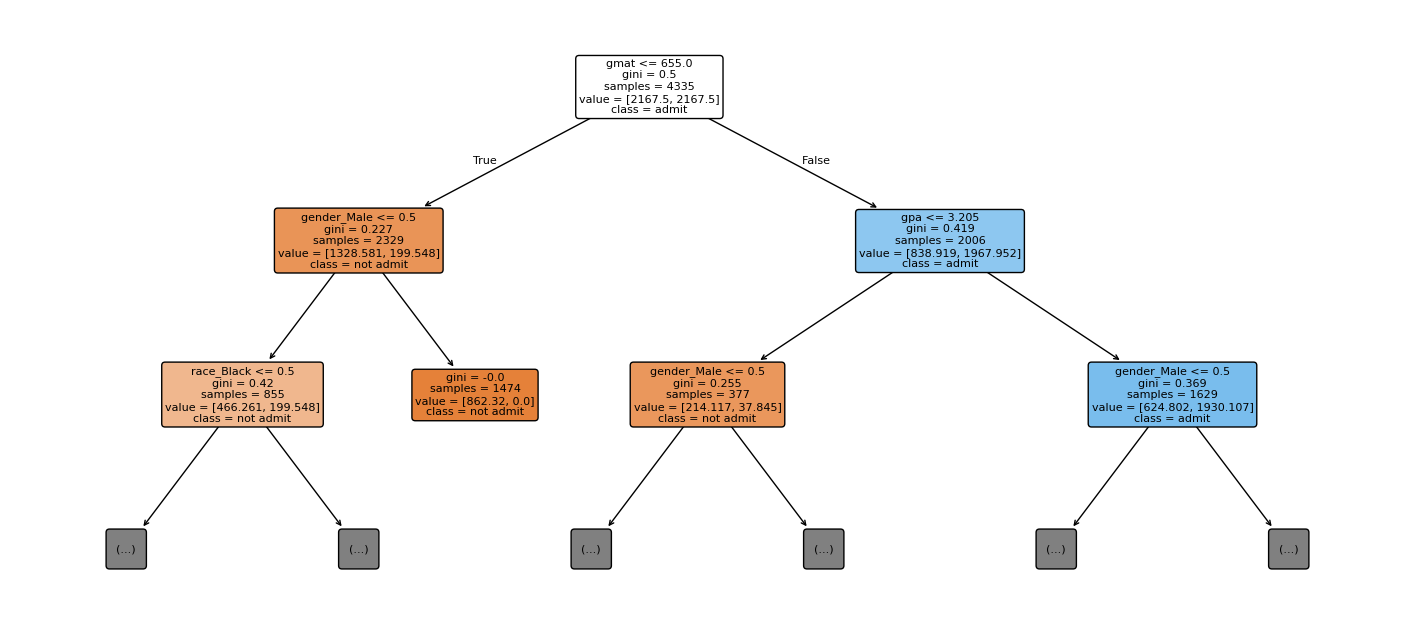

In [66]:
from sklearn.tree import plot_tree

# โชว์แค่ 2 ชั้นพอ ทั้งต้น (depth 8) พิมพ์ออกมาอ่านไม่ออก
plt.figure(figsize=(18, 8))
plot_tree(tree, max_depth=2, feature_names=X_train.columns,
          class_names=['not admit', 'admit'], filled=True, rounded=True, fontsize=8)
plt.show()

## 9. Random forest

In [ ]:
%%time
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            class_weight='balanced_subsample',
                            oob_score=True,    
                            random_state=777, n_jobs=-1)
rf.fit(X_train, y_train)

print("oob score :", rf.oob_score_)

oob score : 0.7670126874279123
CPU times: total: 1.17 s
Wall time: 775 ms


In [68]:
evaluate('Random forest', rf)

[[1206  383]
 [  53  217]] 

              precision    recall  f1-score   support

           0      0.958     0.759     0.847      1589
           1      0.362     0.804     0.499       270

    accuracy                          0.765      1859
   macro avg      0.660     0.781     0.673      1859
weighted avg      0.871     0.765     0.796      1859

AUC = 0.8507


In [69]:
top_features(rf)

,Feature,Value
1,gmat,0.443050
0,gpa,0.302619
3,gender_Male,0.068402
2,work_exp,0.036570
6,race_Black,0.017507
4,major_Humanities,0.014453
8,race_International,0.014048
5,major_STEM,0.013842
11,work_industry_Consulting,0.011722
10,race_White,0.011062


## 10. Gradient boosting

In [70]:
%%time
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                random_state=777)
gb.fit(X_train, y_train, sample_weight=compute_sample_weight('balanced', y_train))

CPU times: total: 875 ms
Wall time: 862 ms


,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``,

In [71]:
evaluate('Gradient boosting', gb)

[[1143  446]
 [  36  234]] 

              precision    recall  f1-score   support

           0      0.969     0.719     0.826      1589
           1      0.344     0.867     0.493       270

    accuracy                          0.741      1859
   macro avg      0.657     0.793     0.659      1859
weighted avg      0.879     0.741     0.777      1859

AUC = 0.8451


In [72]:
top_features(gb)

,Feature,Value
1,gmat,0.601661
0,gpa,0.198863
3,gender_Male,0.101911
6,race_Black,0.025674
2,work_exp,0.014942
7,race_Hispanic,0.012602
9,race_Other,0.006216
8,race_International,0.006170
13,work_industry_Financial Services,0.004996
4,major_Humanities,0.003906


## 11. Compare

In [73]:
compare = pd.DataFrame(scores).T
print(compare.round(4).to_string())

                   accuracy  precision  recall      f1     AUC
Decision tree        0.7402     0.3374  0.8185  0.4778  0.8366
Random forest        0.7655     0.3617  0.8037  0.4989  0.8507
Gradient boosting    0.7407     0.3441  0.8667  0.4926  0.8451


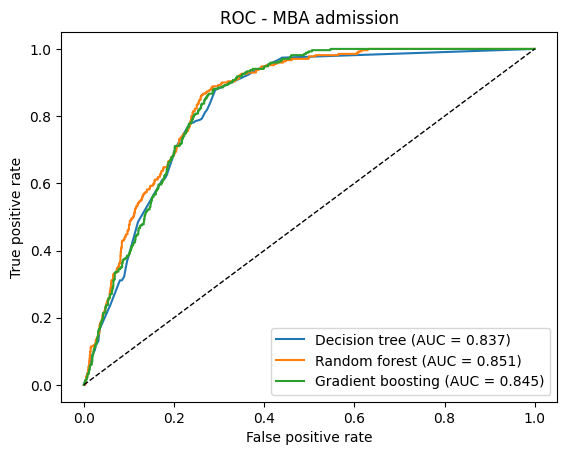

In [ ]:
ax = plt.subplot(111)

for name, (fpr, tpr) in curves.items():
    ax.plot(fpr, tpr, label="%s (AUC = %.3f)" % (name, scores[name]['AUC']))

ax.plot([0, 1], [0, 1], 'k--', lw=1)     
plt.title('ROC - MBA admission')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()

## 12. Summary

- โมเดลที่ AUC ดีที่สุดคือ Random forest (AUC = 0.851) รองลงมาคือ Gradient boosting เเละ Decision tree
- ตัวแปรที่ตัดสินผล admit มากที่สุดคือ gmat กับ gpa ที่ตรงกันจากทั้ง 3 โมเดล
- accuracy ทุกโมเดลอยู่ประมาณ 0.75 แต่ precision ของฝั่ง admit ต่ำกว่ามาก เพราะว่าเราใช้ class_weight='balanced' (ข้อมูลมัน imbalance) ซึ่งเราเเลก precision ไปเอา recall ที่สำคัญกว่า
- เพราะในมุมมองของคนคัดใบสมัคร recall สำคัญกว่า precision เนื่องจากไม่ต้องการ False Negative ที่ คนที่ได้ admit จริงแต่โมเดลบอกไม่ผ่าน